# 07 — Makinat me vektorë mbështetës (SVM)

        **Pyetja udhëheqëse:** Si gjejmë jo vetëm një kufi ndarës, por kufirin me margjinën më të madhe?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të kuptohet hiperplani dhe margjina.
- Të interpretohen vektorët mbështetës.
- Të studiohet parametri C.
- Të vizualizohet efekti i kernelit RBF.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

## Pse kjo temë është e nevojshme?

SVM e formulon klasifikimin si problem gjeometrik dhe optimizimi: ndër shumë kufij të mundshëm kërkojmë atë që lë margjinën më të madhe. Kjo e bën algoritmin një shembull të mirë të lidhjes së algjebrës lineare, optimizimit dhe përgjithësimit.

Do të ndërtojmë intuitën për hiperplanin, margjinën, parametrin C dhe kernelët. Vektorët mbështetës janë pikërisht mostrat që mbajnë informacionin kritik për pozicionin e kufirit.

### Si duhet lexuar ky notebook

Për çdo bllok kodi do të shpjegojmë **pse** kryhet ai hap, çfarë pyetjeje i përgjigjet dhe çfarë duhet të kontrollojmë në dalje. Kodi nuk trajtohet si recetë: çdo grafik dhe çdo metrikë duhet të rikthehet te hipoteza matematikore dhe te interpretimi fizik. Kur një rezultat nuk sillet siç presim, pyetja e parë nuk është “si ta rrisim score-in?”, por “cilën hipotezë të modelit ose të të dhënave po shkelim?”.

### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("07 — Makinat me vektorë mbështetës (SVM)")
print("Seed:", RANDOM_STATE)

07 — Makinat me vektorë mbështetës (SVM)
Seed: 42


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 1. Gjeometria e ndarjes — CORE

### Para se të ekzekutojmë: Të dhëna për të parë gjeometrinë

Zgjedhim një problem dy-dimensional sepse SVM kuptohet më mirë vizualisht. Qëllimi nuk është realizmi i dataset-it, por të shohim hiperplanin, margjinat dhe pikat që i përcaktojnë ato.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

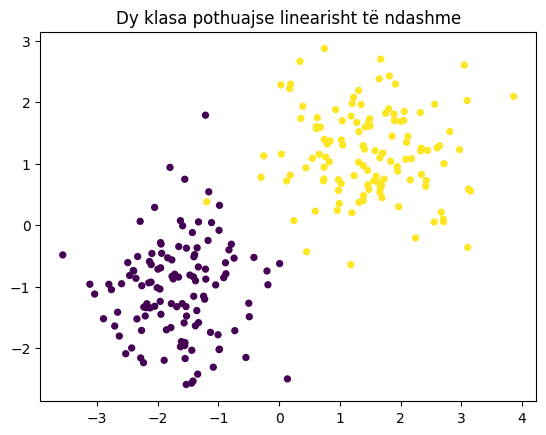

In [2]:
# Qëllimi i këtij blloku: Të dhëna për të parë gjeometrinë.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.datasets import make_blobs
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X,y=make_blobs(n_samples=240,centers=[(-1.6,-1.1),(1.4,1.2)],cluster_std=[0.75,0.8],random_state=RANDOM_STATE)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X[:,0],X[:,1],c=y,s=18)
ax.set_title("Dy klasa pothuajse linearisht të ndashme")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

Një hiperplan shkruhet
$$
\mathbf w^T\mathbf x+b=0.
$$
Distanca e një pike nga hiperplani është
$$
d=\frac{|\mathbf w^T\mathbf x+b|}{\|\mathbf w\|}.
$$
SVM zgjedh kufirin që maksimizon margjinën, duke u mbështetur veçanërisht te pikat më afër kufirit:
**vektorët mbështetës (support vectors)**.

# 2. SVM linear dhe margjina — CORE

### Para se të ekzekutojmë: Hiperplani me margjinë maksimale

Trajnojmë SVM linear dhe nxjerrim $w$ dhe $b$ për të vizatuar kufirin dhe margjinat $w^Tx+b=\pm1$. Rrethojmë vektorët mbështetës për të treguar se jo të gjitha mostrat kanë të njëjtin rol në zgjidhje.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

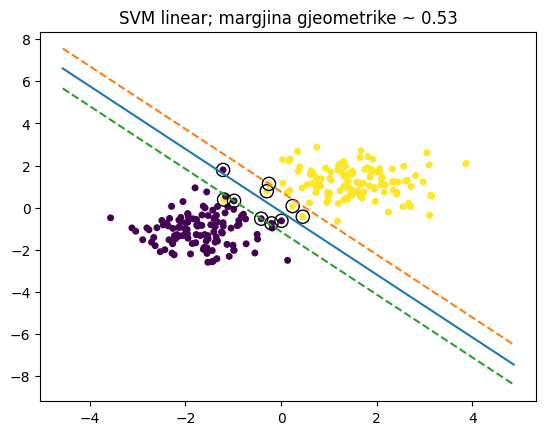

In [3]:
# Qëllimi i këtij blloku: Hiperplani me margjinë maksimale.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.svm import SVC
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
clf=SVC(kernel="linear",C=1.0).fit(X,y)
w=clf.coef_[0]; b=clf.intercept_[0]
xx=np.linspace(X[:,0].min()-1,X[:,0].max()+1,300)
yy=-(w[0]*xx+b)/w[1]
margin=1/np.linalg.norm(w)
yy1=-(w[0]*xx+b-1)/w[1]
yy2=-(w[0]*xx+b+1)/w[1]

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X[:,0],X[:,1],c=y,s=16)
ax.plot(xx,yy)
ax.plot(xx,yy1,linestyle="--"); ax.plot(xx,yy2,linestyle="--")
ax.scatter(clf.support_vectors_[:,0],clf.support_vectors_[:,1],s=90,facecolors="none",edgecolors="black")
ax.set_title(f"SVM linear; margjina gjeometrike ~ {margin:.2f}")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 3. Soft margin dhe parametri C — CORE

### Para se të ekzekutojmë: Hiperplani me margjinë maksimale

Trajnojmë SVM linear dhe nxjerrim $w$ dhe $b$ për të vizatuar kufirin dhe margjinat $w^Tx+b=\pm1$. Rrethojmë vektorët mbështetës për të treguar se jo të gjitha mostrat kanë të njëjtin rol në zgjidhje.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

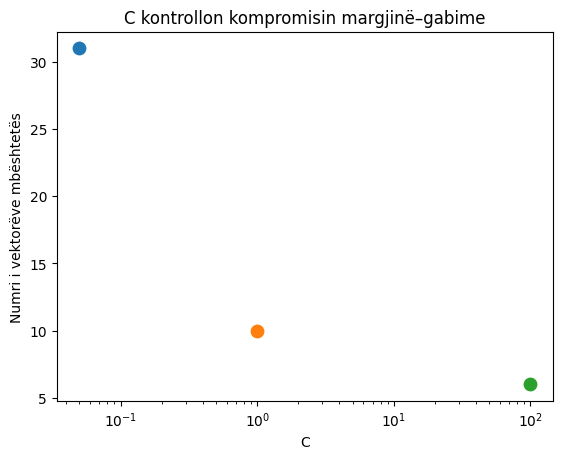

In [4]:
# Qëllimi i këtij blloku: Hiperplani me margjinë maksimale.
Cs=[0.05,1,100]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
for C in Cs:
    # Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
    m=SVC(kernel="linear",C=C).fit(X,y)
    ax.scatter(C,len(m.support_),s=80)
ax.set_xscale("log")
ax.set_xlabel("C"); ax.set_ylabel("Numri i vektorëve mbështetës")
ax.set_title("C kontrollon kompromisin margjinë–gabime")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 4. Hinge loss — CORE

### Para se të ekzekutojmë: Humbja hinge

Grafiku i hinge loss shpjegon pse pikat e klasifikuara saktë por brenda margjinës ende kontribuojnë në humbje. SVM nuk synon vetëm klasifikimin korrekt; synon edhe një margjinë të mjaftueshme.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

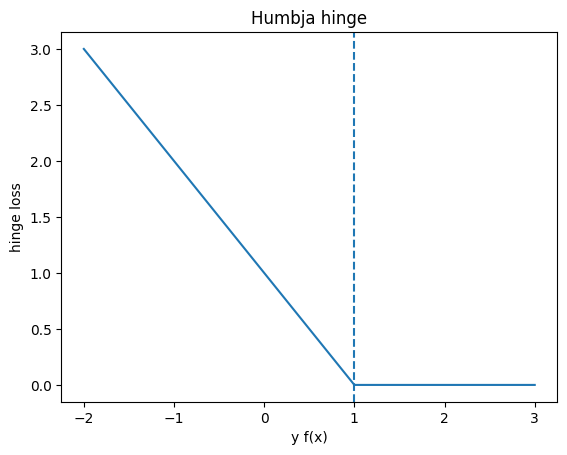

In [5]:
# Qëllimi i këtij blloku: Humbja hinge.
margins=np.linspace(-2,3,400)
hinge=np.maximum(0,1-margins)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(margins,hinge)
ax.axvline(1,linestyle="--")
ax.set_xlabel("y f(x)"); ax.set_ylabel("hinge loss")
ax.set_title("Humbja hinge")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 5. Kernel RBF për kufij jolinearë — CORE

### Para se të ekzekutojmë: Hiperplani me margjinë maksimale

Trajnojmë SVM linear dhe nxjerrim $w$ dhe $b$ për të vizatuar kufirin dhe margjinat $w^Tx+b=\pm1$. Rrethojmë vektorët mbështetës për të treguar se jo të gjitha mostrat kanë të njëjtin rol në zgjidhje.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

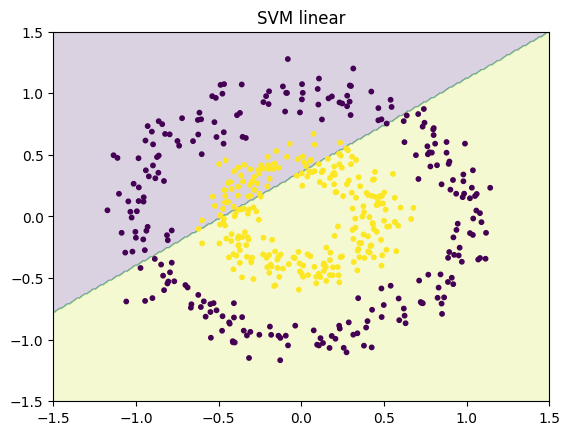

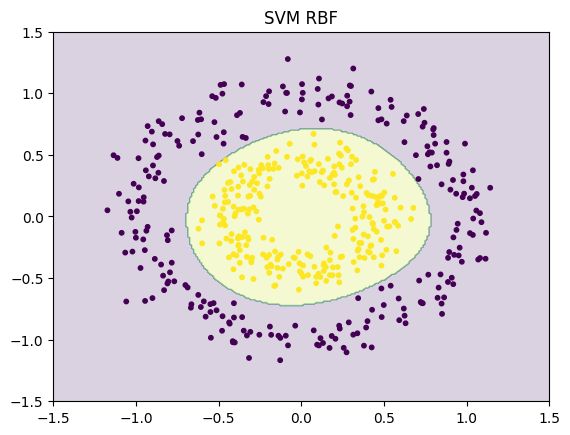

In [6]:
# Qëllimi i këtij blloku: Hiperplani me margjinë maksimale.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.datasets import make_circles
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
Xc,yc=make_circles(n_samples=500,factor=0.45,noise=0.09,random_state=RANDOM_STATE)
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
lin=SVC(kernel="linear").fit(Xc,yc)
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
rbf=SVC(kernel="rbf",gamma="scale",C=2).fit(Xc,yc)

xx,yy=np.meshgrid(np.linspace(-1.5,1.5,250),np.linspace(-1.5,1.5,250))
for name,m in [("linear",lin),("RBF",rbf)]:
    # Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
    zz=m.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    # Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
    fig,ax=plt.subplots()
    ax.contourf(xx,yy,zz,alpha=0.2)
    ax.scatter(Xc[:,0],Xc[:,1],c=yc,s=10)
    ax.set_title(f"SVM {name}")
    plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Sensitivitet ndaj gamma — EXTENDED

### Para se të ekzekutojmë: Gamma dhe shkalla e jolinearitetit

Në RBF, gamma kontrollon sa lokal është ndikimi i një pike. Vlera shumë e madhe mund të krijojë kufij tepër të imët; vlera shumë e vogël mund të jetë tepër e butë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

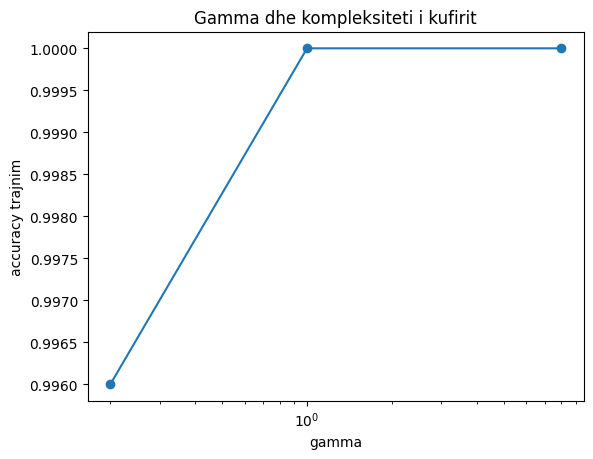

In [7]:
# Qëllimi i këtij blloku: Gamma dhe shkalla e jolinearitetit.
gammas=[0.2,1,8]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
scores=[]
for g in gammas:
    # Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
    m=SVC(kernel="rbf",gamma=g,C=2).fit(Xc,yc)
    scores.append(m.score(Xc,yc))
ax.plot(gammas,scores,marker="o")
ax.set_xscale("log"); ax.set_xlabel("gamma"); ax.set_ylabel("accuracy trajnim")
ax.set_title("Gamma dhe kompleksiteti i kufirit")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 7. Aplikim jo-fizik: klasifikim tekstesh — EXTENDED

SVM-të lineare kanë qenë prej kohësh shumë efektive në hapësira me dimension të lartë, p.sh. tekste të përfaqësuara me mijëra veçori të rralla.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Llogaritni manualisht distancën e një pike nga hiperplani.
2. Analizoni si ndryshon numri i support vectors me C.
3. Krahasoni linear dhe RBF në `make_circles`.
4. Shpjegoni pse scaling është i rëndësishëm për SVM.

        ## B. Ushtrim i plotë
        Krijoni dy regjime dinamike me mbivendosje dhe përdorni grid-search për të zgjedhur C dhe gamma.

        ## C. Playground
        Ndryshoni C, gamma, zhurmën dhe standardizimin.

In [8]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Makinat me vektorë mbështetës** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Distanca nga hiperplani është $|w^Tx+b|/\|w\|$.
- $C$ i madh penalizon fort gabimet dhe zakonisht ngushton margjinën; $C$ i vogël lejon më shumë shkelje.
- Standardizimi është kritik sepse margjina dhe kernelët varen nga distancat në hapësirën e veçorive.